In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import warnings
warnings.filterwarnings('ignore')


In [5]:
df = pd.read_csv("Test.csv")

df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6
2,458996,Female,Yes,69,No,NaN,0.0,Low,1.0,Cat_6
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6
4,459001,Female,No,19,No,Marketing,NaN,Low,4.0,Cat_6


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 2627
Columns: 10


In [7]:
df.columns

Index(['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Profession',
       'Work_Experience', 'Spending_Score', 'Family_Size', 'Var_1'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2627 entries, 0 to 2626
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2627 non-null   int64  
 1   Gender           2627 non-null   str    
 2   Ever_Married     2577 non-null   str    
 3   Age              2627 non-null   int64  
 4   Graduated        2603 non-null   str    
 5   Profession       2589 non-null   str    
 6   Work_Experience  2358 non-null   float64
 7   Spending_Score   2627 non-null   str    
 8   Family_Size      2514 non-null   float64
 9   Var_1            2595 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 205.4 KB


In [9]:
df.describe(include='all')

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
count,2627.000000,2627,2577,2627.000000,2603,2589,2358.000000,2627,2514.000000,2595
unique,NaN,2,2,NaN,2,9,NaN,3,NaN,7
top,NaN,Male,Yes,NaN,Yes,Artist,NaN,Low,NaN,Cat_6
freq,NaN,1424,1520,NaN,1602,802,NaN,1616,NaN,1672
mean,463433.918919,NaN,NaN,43.649791,NaN,NaN,2.552587,NaN,2.825378,NaN
std,2618.245698,NaN,NaN,16.967015,NaN,NaN,3.341094,NaN,1.551906,NaN
min,458989.000000,NaN,NaN,18.000000,NaN,NaN,0.000000,NaN,1.000000,NaN
25%,461162.500000,NaN,NaN,30.000000,NaN,NaN,0.000000,NaN,2.000000,NaN
50%,463379.000000,NaN,NaN,41.000000,NaN,NaN,1.000000,NaN,2.000000,NaN
75%,465696.000000,NaN,NaN,53.000000,NaN,NaN,4.000000,NaN,4.000000,NaN


In [10]:
df.isnull().sum()

ID                   0
Gender               0
Ever_Married        50
Age                  0
Graduated           24
Profession          38
Work_Experience    269
Spending_Score       0
Family_Size        113
Var_1               32
dtype: int64

In [11]:
df.isnull().sum()

ID                   0
Gender               0
Ever_Married        50
Age                  0
Graduated           24
Profession          38
Work_Experience    269
Spending_Score       0
Family_Size        113
Var_1               32
dtype: int64

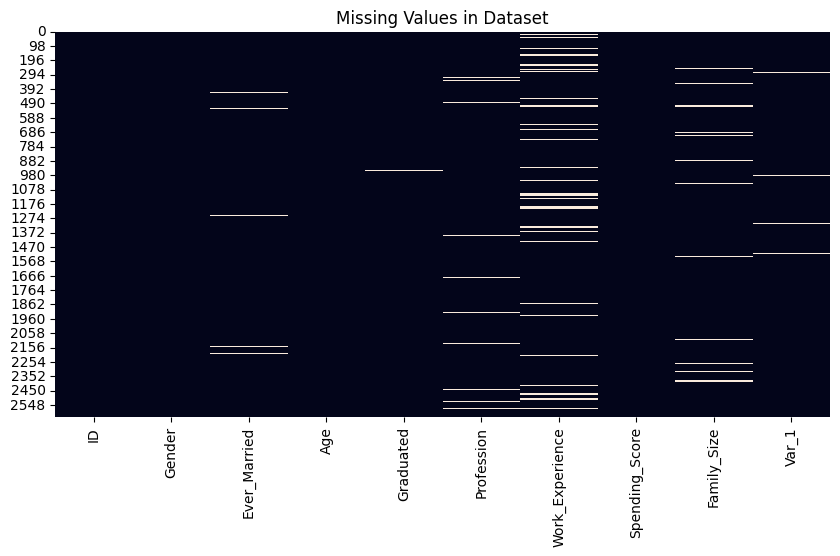

In [12]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")
plt.show()

In [13]:
data = df.copy()

In [14]:
data = data.drop_duplicates()

print("Shape after removing duplicates:", data.shape)

Shape after removing duplicates: (2627, 10)


In [15]:
categorical_columns = [
    'Ever_Married',
    'Graduated',
    'Profession',
    'Var_1'
]

for column in categorical_columns:
    data[column] = data[column].fillna(data[column].mode()[0])

In [16]:
numerical_columns = [
    'Work_Experience',
    'Family_Size'
]

for column in numerical_columns:
    data[column] = data[column].fillna(data[column].median())

In [17]:
data.isnull().sum()

ID                 0
Gender             0
Ever_Married       0
Age                0
Graduated          0
Profession         0
Work_Experience    0
Spending_Score     0
Family_Size        0
Var_1              0
dtype: int64

In [18]:
data.head()


,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6
2,458996,Female,Yes,69,No,Artist,0.0,Low,1.0,Cat_6
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6
4,459001,Female,No,19,No,Marketing,1.0,Low,4.0,Cat_6


In [19]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2627 entries, 0 to 2626
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               2627 non-null   int64  
 1   Gender           2627 non-null   str    
 2   Ever_Married     2627 non-null   str    
 3   Age              2627 non-null   int64  
 4   Graduated        2627 non-null   str    
 5   Profession       2627 non-null   str    
 6   Work_Experience  2627 non-null   float64
 7   Spending_Score   2627 non-null   str    
 8   Family_Size      2627 non-null   float64
 9   Var_1            2627 non-null   str    
dtypes: float64(2), int64(2), str(6)
memory usage: 205.4 KB


In [20]:
data.describe()

,ID,Age,Work_Experience,Family_Size
count,2627.000000,2627.000000,2627.000000,2627.000000
mean,463433.918919,43.649791,2.393605,2.789874
std,2618.245698,16.967015,3.200165,1.527360
min,458989.000000,18.000000,0.000000,1.000000
25%,461162.500000,30.000000,0.000000,2.000000
50%,463379.000000,41.000000,1.000000,2.000000
75%,465696.000000,53.000000,3.000000,4.000000
max,467968.000000,89.000000,14.000000,9.000000


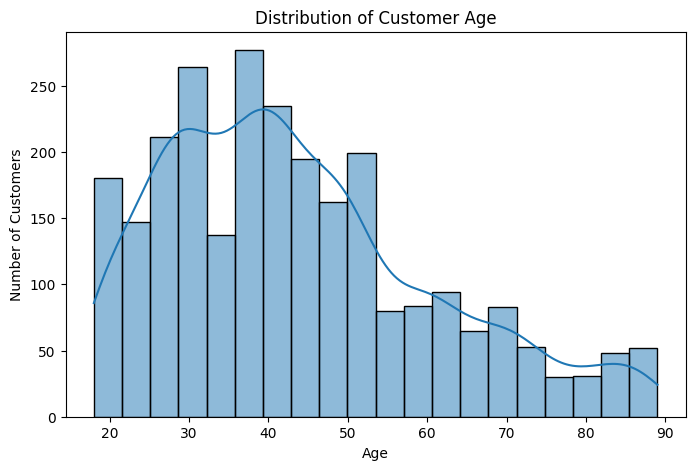

In [21]:
plt.figure(figsize=(8, 5))

sns.histplot(data['Age'], bins=20, kde=True)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

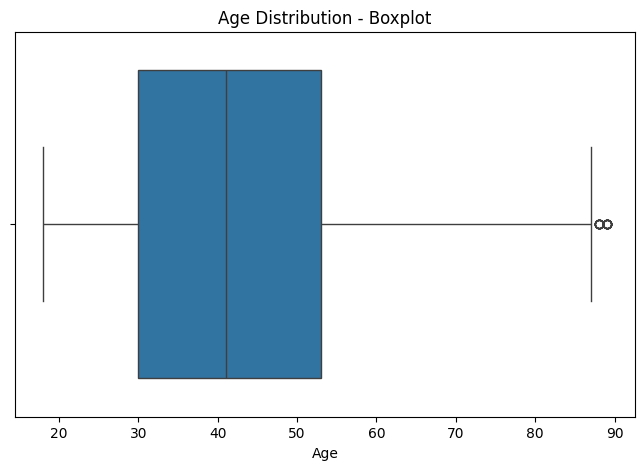

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=data['Age'])

plt.title("Age Distribution - Boxplot")
plt.xlabel("Age")

plt.show()

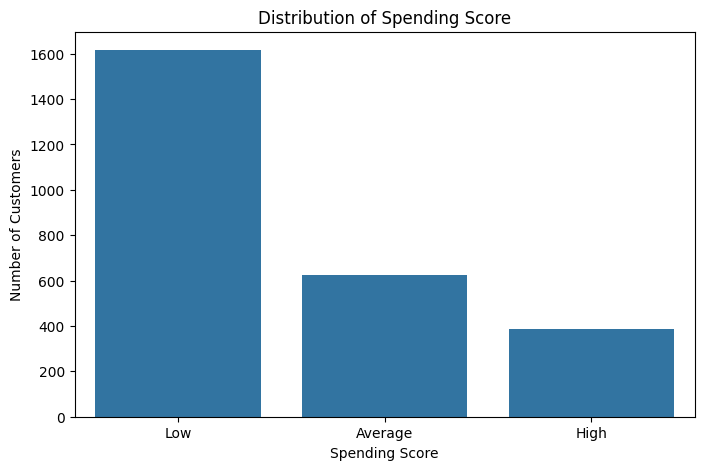

In [23]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=data,
    x='Spending_Score',
    order=data['Spending_Score'].value_counts().index
)

plt.title("Distribution of Spending Score")
plt.xlabel("Spending Score")
plt.ylabel("Number of Customers")

plt.show()

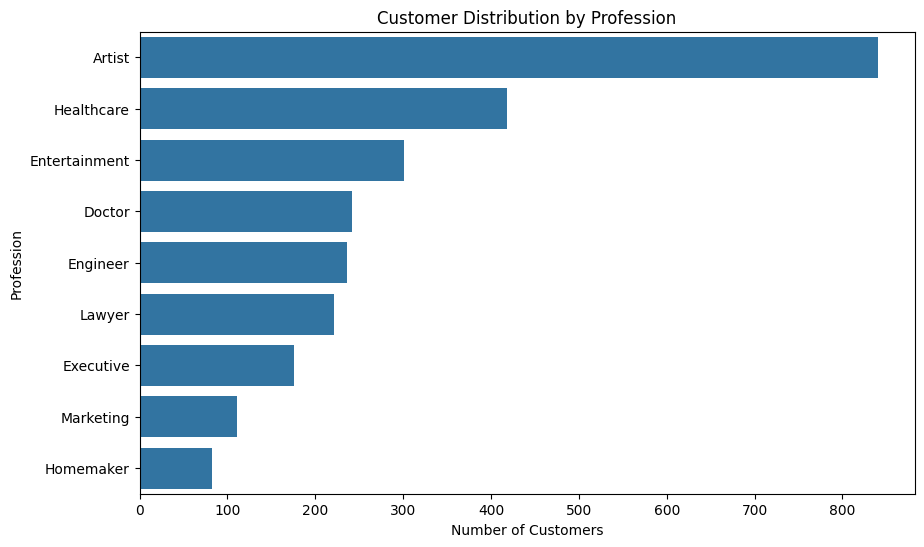

In [24]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    y='Profession',
    order=data['Profession'].value_counts().index
)

plt.title("Customer Distribution by Profession")
plt.xlabel("Number of Customers")
plt.ylabel("Profession")

plt.show()


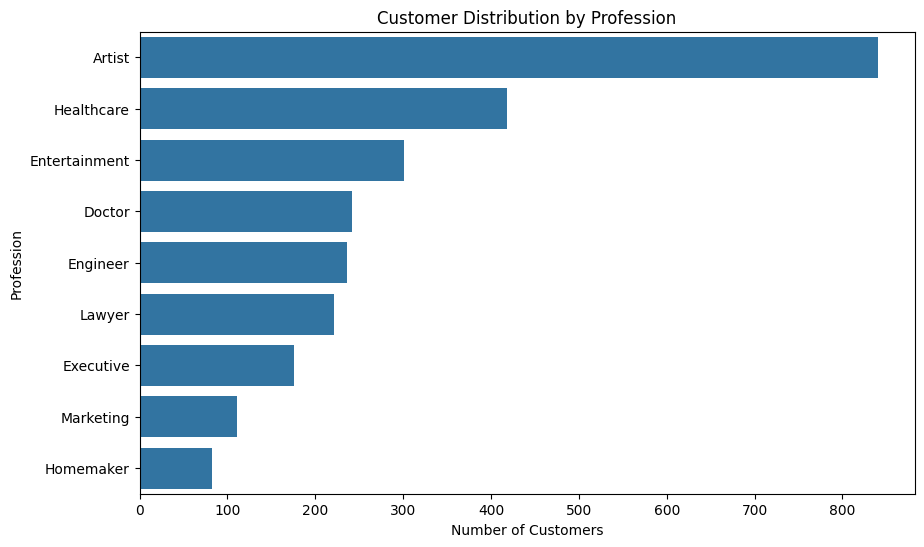

In [25]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=data,
    y='Profession',
    order=data['Profession'].value_counts().index
)

plt.title("Customer Distribution by Profession")
plt.xlabel("Number of Customers")
plt.ylabel("Profession")

plt.show()

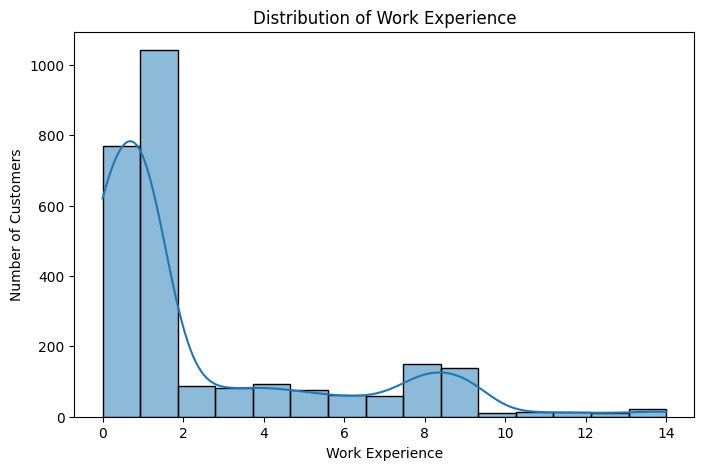

In [26]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data['Work_Experience'],
    bins=15,
    kde=True
)

plt.title("Distribution of Work Experience")
plt.xlabel("Work Experience")
plt.ylabel("Number of Customers")

plt.show()

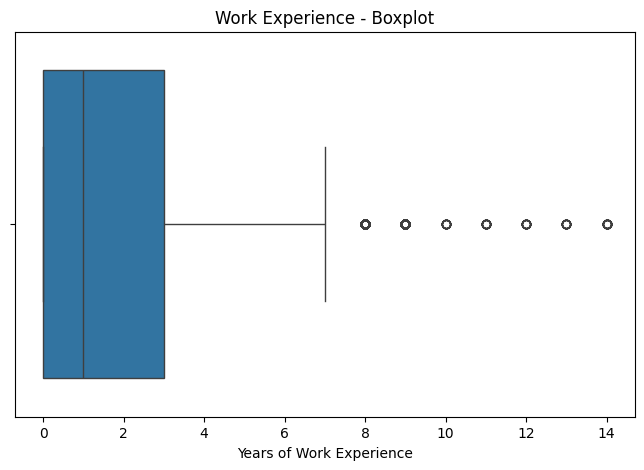

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=data['Work_Experience'])

plt.title("Work Experience - Boxplot")
plt.xlabel("Years of Work Experience")

plt.show()

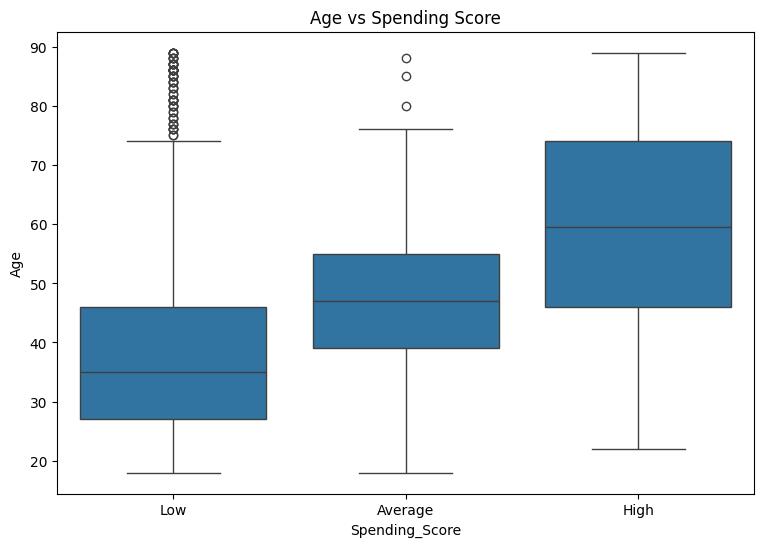

In [28]:
plt.figure(figsize=(9, 6))

sns.boxplot(
    data=data,
    x='Spending_Score',
    y='Age'
)

plt.title("Age vs Spending Score")

plt.show()

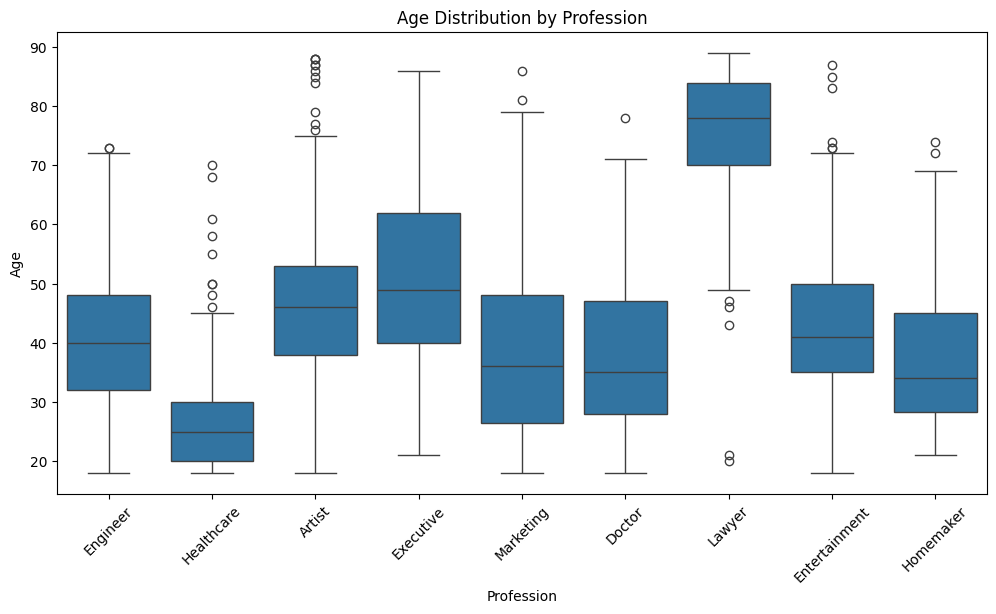

In [29]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=data,
    x='Profession',
    y='Age'
)

plt.title("Age Distribution by Profession")
plt.xticks(rotation=45)

plt.show()

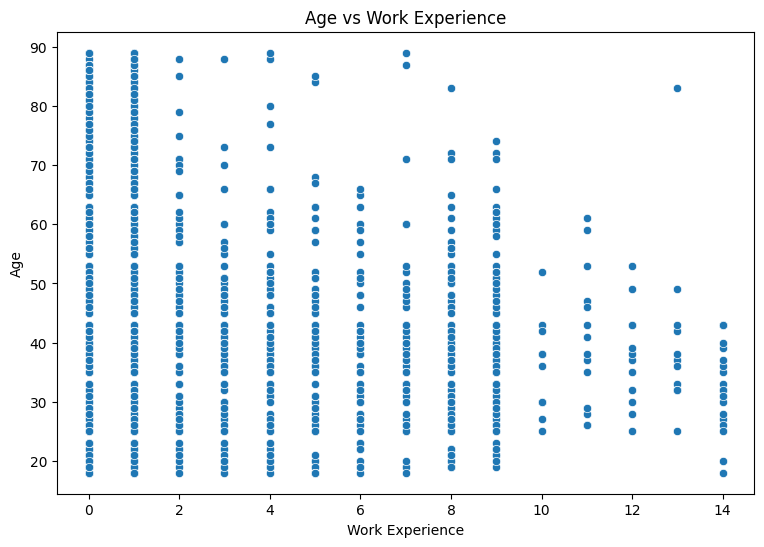

In [30]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=data,
    x='Work_Experience',
    y='Age'
)

plt.title("Age vs Work Experience")
plt.xlabel("Work Experience")
plt.ylabel("Age")

plt.show()

In [32]:
spending_mapping = {
    'Low': 0,
    'Average': 1,
    'High': 2
}

data['Spending_Score_Encoded'] = data['Spending_Score'].map(spending_mapping)

In [34]:
data[['Spending_Score', 'Spending_Score_Encoded']].drop_duplicates()

,Spending_Score,Spending_Score_Encoded
0,Low,0
1,Average,1
3,High,2


In [35]:
binary_mapping = {
    'Yes': 1,
    'No': 0
}

data['Ever_Married_Encoded'] = data['Ever_Married'].map(binary_mapping)
data['Graduated_Encoded'] = data['Graduated'].map(binary_mapping)

In [36]:
gender_mapping = {
    'Male': 0,
    'Female': 1
}

data['Gender_Encoded'] = data['Gender'].map(gender_mapping)

In [37]:
data[
    [
        'Gender',
        'Gender_Encoded',
        'Ever_Married',
        'Ever_Married_Encoded',
        'Graduated',
        'Graduated_Encoded',
        'Spending_Score',
        'Spending_Score_Encoded'
    ]
].head()

,Gender,Gender_Encoded,Ever_Married,Ever_Married_Encoded,Graduated,Graduated_Encoded,Spending_Score,Spending_Score_Encoded
0,Female,1,Yes,1,Yes,1,Low,0
1,Male,0,Yes,1,Yes,1,Average,1
2,Female,1,Yes,1,No,0,Low,0
3,Male,0,Yes,1,No,0,High,2
4,Female,1,No,0,No,0,Low,0


In [38]:
data_encoded = pd.get_dummies(
    data,
    columns=['Profession', 'Var_1'],
    drop_first=True,
    dtype=int
)

In [39]:
data_encoded.columns

Index(['ID', 'Gender', 'Ever_Married', 'Age', 'Graduated', 'Work_Experience',
       'Spending_Score', 'Family_Size', 'Spending_Score_Encoded',
       'Ever_Married_Encoded', 'Graduated_Encoded', 'Gender_Encoded',
       'Profession_Doctor', 'Profession_Engineer', 'Profession_Entertainment',
       'Profession_Executive', 'Profession_Healthcare', 'Profession_Homemaker',
       'Profession_Lawyer', 'Profession_Marketing', 'Var_1_Cat_2',
       'Var_1_Cat_3', 'Var_1_Cat_4', 'Var_1_Cat_5', 'Var_1_Cat_6',
       'Var_1_Cat_7'],
      dtype='str')

In [44]:
features = [
    'Gender_Encoded',
    'Ever_Married_Encoded',
    'Age',
    'Graduated_Encoded',
    'Work_Experience',
    'Family_Size',
    'Spending_Score_Encoded'
]

X = data_encoded[features]

In [45]:
X.head()

,Gender_Encoded,Ever_Married_Encoded,Age,Graduated_Encoded,Work_Experience,Family_Size,Spending_Score_Encoded
0,1,1,36,1,0.0,1.0,0
1,0,1,37,1,8.0,4.0,1
2,1,1,69,0,0.0,1.0,0
3,0,1,59,0,11.0,2.0,2
4,1,0,19,0,1.0,4.0,0


In [46]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [47]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

X_scaled_df.head()

,Gender_Encoded,Ever_Married_Encoded,Age,Graduated_Encoded,Work_Experience,Family_Size,Spending_Score_Encoded
0,1.087983,0.820517,-0.450948,0.784615,-0.748105,-1.172097,-0.721759
1,-0.919132,0.820517,-0.391999,0.784615,1.752242,0.792450,0.635478
2,1.087983,0.820517,1.494372,-1.274510,-0.748105,-1.172097,-0.721759
3,-0.919132,0.820517,0.904881,-1.274510,2.689872,-0.517248,1.992715
4,1.087983,-1.218744,-1.453083,-1.274510,-0.435562,0.792450,-0.721759


In [48]:
wcss = []

for k in range(1, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)

    wcss.append(kmeans.inertia_)

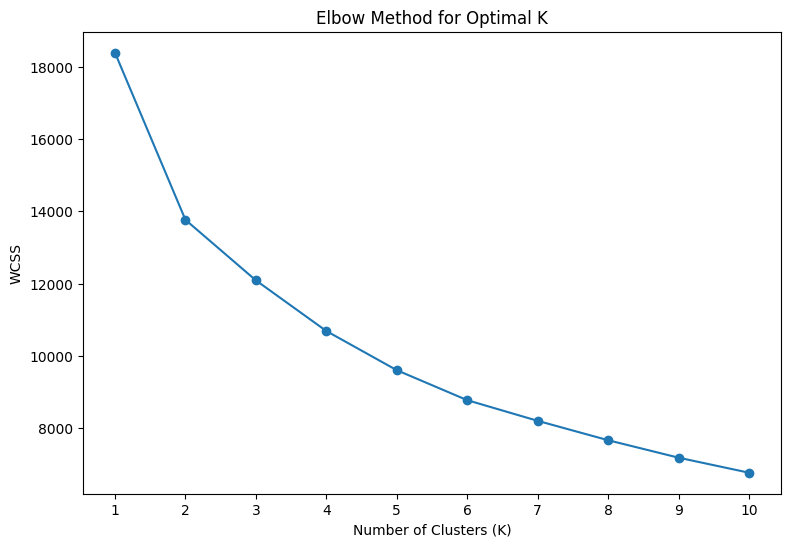

In [49]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.xticks(range(1, 11))

plt.show()

In [50]:
silhouette_scores = []

for k in range(2, 11):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(
        X_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"K = {k}, Silhouette Score = {score:.4f}"
    )

K = 2, Silhouette Score = 0.2489
K = 3, Silhouette Score = 0.2153
K = 4, Silhouette Score = 0.2124
K = 5, Silhouette Score = 0.2216
K = 6, Silhouette Score = 0.2242
K = 7, Silhouette Score = 0.2246
K = 8, Silhouette Score = 0.2401
K = 9, Silhouette Score = 0.2454
K = 10, Silhouette Score = 0.2393


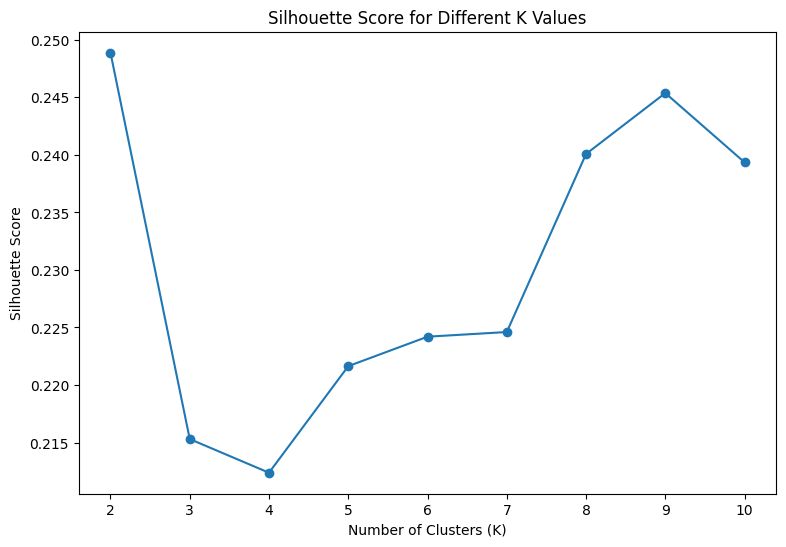

In [51]:
plt.figure(figsize=(9, 6))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.xticks(range(2, 11))

plt.show()

In [53]:
best_k_silhouette = range(2, 11)[
    np.argmax(silhouette_scores)
]

best_k_silhouette

2

In [54]:
optimal_k = best_k_silhouette

print("Optimal number of clusters:", optimal_k)

Optimal number of clusters: 2


In [55]:
final_kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

cluster_labels = final_kmeans.fit_predict(X_scaled)

In [56]:
data['Cluster'] = cluster_labels

In [57]:
data.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Spending_Score_Encoded,Ever_Married_Encoded,Graduated_Encoded,Gender_Encoded,Cluster
0,458989,Female,Yes,36,Yes,Engineer,0.0,Low,1.0,Cat_6,0,1,1,1,0
1,458994,Male,Yes,37,Yes,Healthcare,8.0,Average,4.0,Cat_6,1,1,1,0,0
2,458996,Female,Yes,69,No,Artist,0.0,Low,1.0,Cat_6,0,1,0,1,0
3,459000,Male,Yes,59,No,Executive,11.0,High,2.0,Cat_6,2,1,0,0,0
4,459001,Female,No,19,No,Marketing,1.0,Low,4.0,Cat_6,0,0,0,1,1


In [58]:
cluster_counts = data['Cluster'].value_counts().sort_index()

cluster_counts

Cluster
0    1516
1    1111
Name: count, dtype: int64

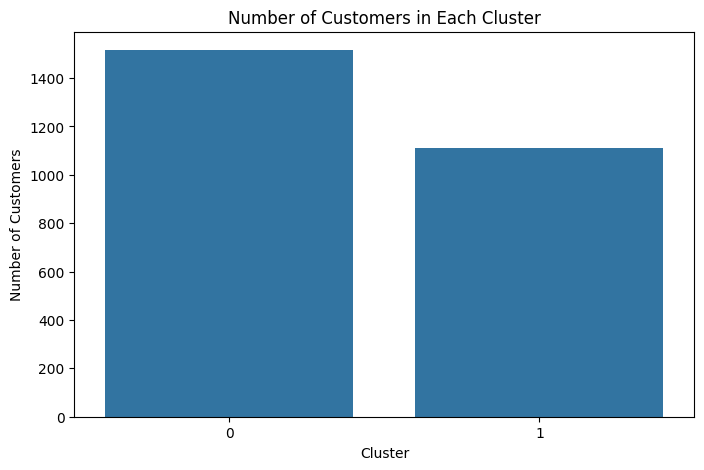

In [60]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Number of Customers in Each Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")

plt.show()

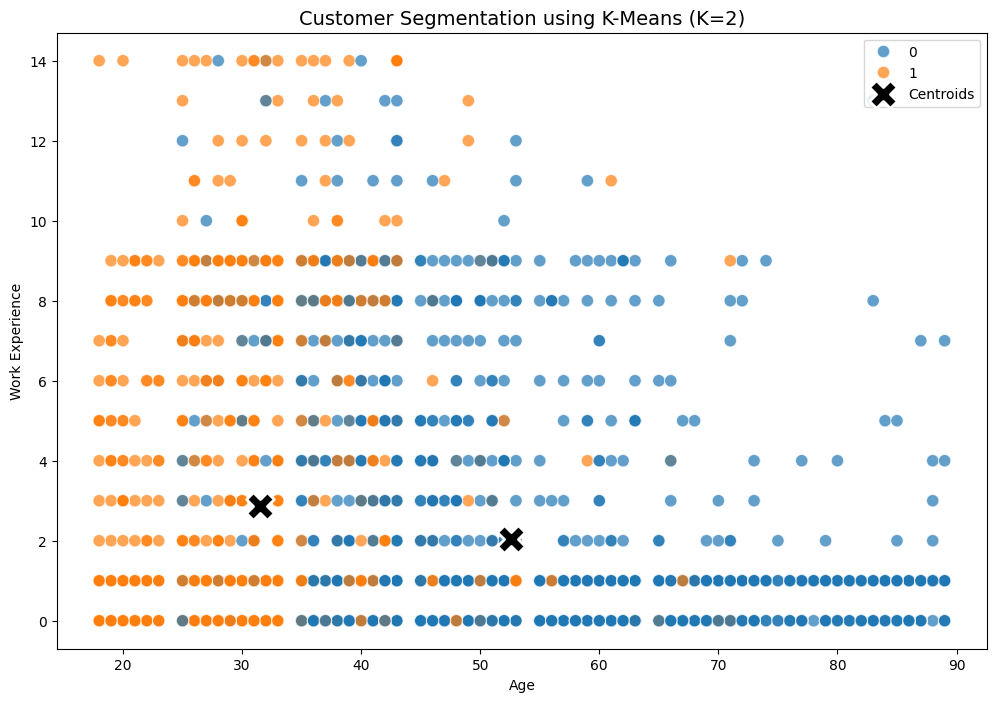

In [62]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=data,
    x='Age',
    y='Work_Experience',
    hue='Cluster',
    palette='tab10',
    s=80,
    alpha=0.7
)

# Calculate centroids in the original feature space
centroid_scaled = final_kmeans.cluster_centers_

centroid_original = scaler.inverse_transform(
    centroid_scaled
)

age_index = features.index('Age')
work_index = features.index('Work_Experience')

centroid_age = centroid_original[:, age_index]
centroid_work = centroid_original[:, work_index]

plt.scatter(
    centroid_age,
    centroid_work,
    marker='X',
    s=400,
    c='black',
    edgecolors='white',
    linewidths=2,
    label='Centroids'
)

plt.title(
    f"Customer Segmentation using K-Means (K={optimal_k})",
    fontsize=14
)

plt.xlabel("Age")
plt.ylabel("Work Experience")

plt.legend()

plt.show()

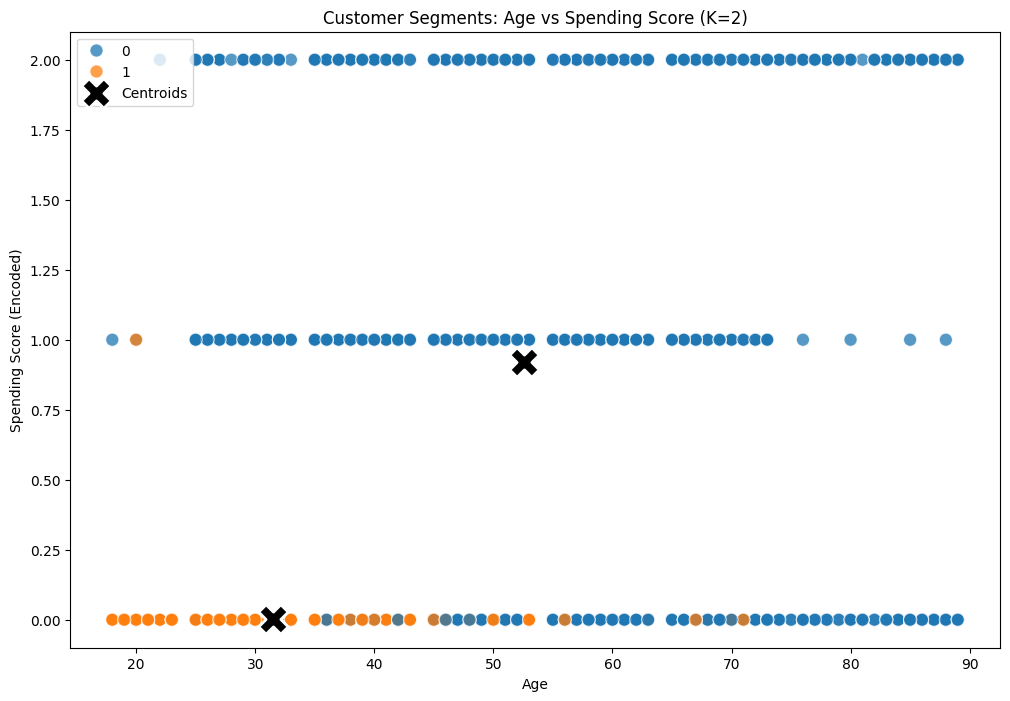

In [63]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    data=data,
    x='Age',
    y='Spending_Score_Encoded',
    hue='Cluster',
    palette='tab10',
    s=90,
    alpha=0.75
)

# Centroids
spending_index = features.index('Spending_Score_Encoded')

centroid_spending = centroid_original[:, spending_index]

plt.scatter(
    centroid_age,
    centroid_spending,
    marker='X',
    s=450,
    c='black',
    edgecolors='white',
    linewidths=2,
    label='Centroids'
)

plt.title(
    f"Customer Segments: Age vs Spending Score (K={optimal_k})"
)

plt.xlabel("Age")
plt.ylabel("Spending Score (Encoded)")

plt.legend()

plt.show()

In [64]:
gender_cluster = pd.crosstab(
    data['Cluster'],
    data['Gender'],
    normalize='index'
) * 100

gender_cluster.round(2)

Gender,Female,Male
Cluster,,
0,41.09,58.91
1,52.21,47.79
